# 3 · What explains efficiency? Second-stage panel regressions
The pure-technical (VRS) DEA scores of OIC economies from notebook 1 are regressed on country characteristics (Penn World Table):

| Variable | Meaning |
|---|---|
| `hc` | human-capital index (years of schooling and returns to education) |
| `openness` | exports + imports share of GDP (PPP) |
| `gov_share` | government consumption share |
| `inv_share` | investment (gross capital formation) share |
| `labour_share` | labour share of income |
| `log_pop` | log population (size) |

Estimators: pooled OLS, entity fixed effects, two-way fixed effects and random effects, all with **country-clustered** standard errors. Model choice uses a robust **Hausman (Mundlak)** test and the **Breusch-Pagan LM** test, and a **fractional logit** (Papke-Wooldridge) is run as a robustness check because scores are bounded in (0, 1].

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
pwt = pd.read_csv("../data/pwt1001_subset.csv.gz")
oic = pd.read_csv("../data/oic_members.csv")
pwt = pwt[(pwt.year >= 2000)].dropna(subset=["rgdpna", "rnna", "emp", "hc"])
pwt = pwt[(pwt.emp > 0.1)]                                   # drop micro-states (< 100k workers)
pwt["labour_hc"] = pwt.emp * pwt.hc                          # human-capital-adjusted labour
pwt["oic"] = pwt.countrycode.isin(oic.iso3)
print(f"{pwt.countrycode.nunique()} countries ({pwt[pwt.oic].countrycode.nunique()} OIC members), {pwt.year.min()}-{pwt.year.max()}")
from effpanel import panel

144 countries (41 OIC members), 2000-2019


In [2]:
eff = pd.read_csv("../data/dea_scores.csv")
d = eff[eff.oic].merge(pwt, on=["countrycode", "year", "country", "oic"])
d["openness"] = d.csh_x + d.csh_m.abs()
d = d.assign(gov_share=d.csh_g, inv_share=d.csh_i, labour_share=d.labsh, log_pop=np.log(d["pop"]),
             score=d["VRS (pure technical)"]).dropna(subset=["hc", "openness", "gov_share", "inv_share", "labour_share", "score"])
xs = ["hc", "openness", "gov_share", "inv_share", "labour_share", "log_pop"]
df = d.set_index(["countrycode", "year"])[["score"] + xs]
print(f"{df.index.get_level_values(0).nunique()} OIC countries, {len(df)} country-years")
df.describe().T.round(3)

29 OIC countries, 580 country-years


,count,mean,std,min,25%,50%,75%,max
score,580.0,0.603,0.234,0.072,0.447,0.568,0.744,1.000
hc,580.0,2.079,0.604,1.069,1.579,2.076,2.478,3.550
openness,580.0,0.407,0.247,0.000,0.216,0.355,0.535,1.289
gov_share,580.0,0.161,0.053,0.005,0.126,0.154,0.194,0.423
inv_share,580.0,0.211,0.094,0.023,0.145,0.198,0.269,0.585
labour_share,580.0,0.439,0.139,0.090,0.335,0.449,0.504,0.903
log_pop,580.0,2.681,1.326,-0.523,1.833,2.766,3.429,5.601


In [3]:
res = panel.fit_all(df, "score", xs)
print(panel.comparison_table(res))

                                            Model Comparison                                           
                            Pooled OLS Fixed effects (entity) Fixed effects (two-way)    Random effects
-------------------------------------------------------------------------------------------------------
Dep. Variable                    score                  score                   score             score
Estimator                    PooledOLS               PanelOLS                PanelOLS     RandomEffects
No. Observations                   580                    580                     580               580
Cov. Est.                    Clustered              Clustered               Clustered         Clustered
R-squared                       0.2360                 0.1864                  0.2944            0.1767
R-Squared (Within)             -0.1986                 0.1864                 -1.1367            0.1856
R-Squared (Between)             0.2782                -0.0565   

In [4]:
h = panel.hausman(df, "score", xs); lm = panel.breusch_pagan_lm(df, "score", xs)
pd.DataFrame({"Robust Hausman (Mundlak)": {"statistic": h["chi2"], "dof": h["dof"], "p-value": h["p_value"], "decision": f"prefer {h['preferred']}"},
              "Breusch-Pagan LM (RE vs pooled)": {"statistic": lm["LM"], "dof": 1, "p-value": lm["p_value"],
                                                  "decision": "individual effects matter" if lm["p_value"] < 0.05 else "pooled OLS adequate"}}).T

,statistic,dof,p-value,decision
Robust Hausman (Mundlak),11.916954,6,0.063847,prefer Random effects
Breusch-Pagan LM (RE vs pooled),4016.974085,1,0.0,individual effects matter


In [5]:
fl = panel.fractional_logit(df, "score", xs)
X = df[xs]; Xc = np.column_stack([np.ones(len(X)), X.values])
p = fl.predict(Xc)
ame = pd.Series((fl.params[1:][None, :] * (p * (1 - p))[:, None]).mean(axis=0), index=xs)   # average marginal effects
pd.DataFrame({"coef": fl.params[1:], "std err": fl.bse[1:], "p-value": fl.pvalues[1:], "avg marginal effect": ame.values}, index=xs).round(4)

,coef,std err,p-value,avg marginal effect
hc,0.0378,0.3115,0.9033,0.0086
openness,-0.1219,0.6729,0.8563,-0.0276
gov_share,-2.5540,2.0284,0.2080,-0.5784
inv_share,-0.8408,1.8350,0.6468,-0.1904
labour_share,-3.7946,1.1558,0.0010,-0.8594
log_pop,-0.0910,0.1182,0.4413,-0.0206


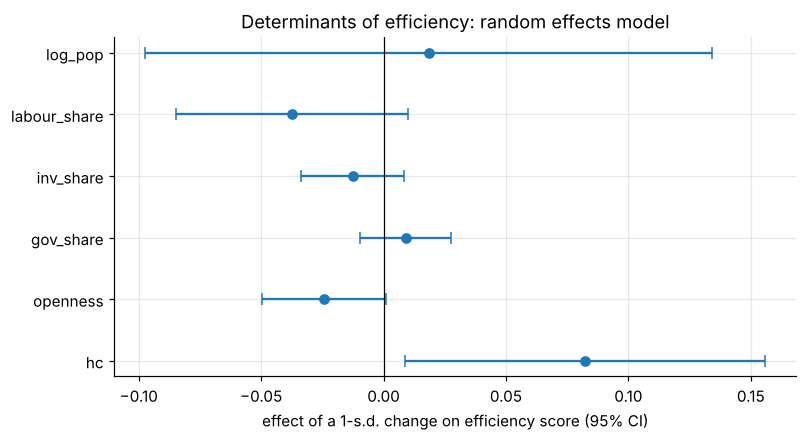

In [6]:
best = res["Fixed effects (entity)"] if h["preferred"] == "Fixed effects" else res["Random effects"]
ci = best.conf_int().drop(index="const", errors="ignore")
coef = best.params.drop("const", errors="ignore")
std = df[xs].std()
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar((coef * std).values, range(len(coef)), xerr=[(coef - ci.iloc[:, 0]) * std, (ci.iloc[:, 1] - coef) * std], fmt="o", capsize=4)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(coef))); ax.set_yticklabels(coef.index)
ax.set_xlabel("effect of a 1-s.d. change on efficiency score (95% CI)"); ax.set_title(f"Determinants of efficiency: {h['preferred'].lower()} model")
plt.savefig(IMG / "panel_coefficients.png", bbox_inches="tight"); plt.show()

**Findings (OIC panel, 2000-2019)**
* **Model choice:** the Breusch-Pagan LM test strongly rejects pooled OLS, so country effects matter. The robust Hausman test does not reject random effects at 5% (p ≈ 0.06), so RE is preferred, with entity FE as a close robustness check: their coefficients are almost identical.
* **Human capital** is the most robust positive correlate of efficiency in the within-country models (RE and FE). Countries that raised schooling and its returns moved closer to the frontier.
* **Openness** has a small *negative* association in RE/FE. That likely reflects resource exporters, whose large trade shares come with low non-resource productivity.
* Pooled OLS and the pooled fractional logit attach a strongly negative coefficient to the **labour share**. It disappears once country effects are controlled for, so it is a cross-country composition effect, not a within-country driver.

**Method notes and caveats**
* The Mundlak form of the Hausman test stays valid with clustered errors, unlike the classical version, which can even produce negative statistics.
* Two-step DEA regressions have a known complication: DEA scores are serially correlated estimates, so conventional inference is approximate. Simar & Wilson (2007) propose a bootstrap fix; the fractional-logit check here guards against the bounded-dependent-variable problem.
* Coefficients are **associations**, not causal effects. Reverse causality (efficient economies attract trade and investment) is likely. Instrumental variables or lagged regressors are natural extensions.